Seção de Análise Exploratória

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Identificar o número de registros, os atributos e seus respectivos tipos.

raiz = Path.cwd().resolve()
if not (raiz / "dados" / "online_shoppers_intention.csv").is_file():
    raiz = raiz.parent
if not (raiz / "dados" / "online_shoppers_intention.csv").is_file():
    raise FileNotFoundError("Execute a partir da raiz do projeto ou da pasta script.")
saida = raiz / "resultados"
saida.mkdir(exist_ok=True)

df = pd.read_csv(raiz / "dados" / "online_shoppers_intention.csv")

print("Dimensões:", df.shape)

display(df.head())

# Identificamos que a variavel-alvo é a coluna "Revenue", que indica se o usuário realizou uma compra ou não.

Dimensões: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [2]:
# Identificar o número de valores ausentes em cada atributo.

ausentes = df.isnull().sum()

print(ausentes)
print("Total de ausentes:", ausentes.sum())

# Identificar o número de registros duplicados.

duplicados = df.duplicated().sum()

print("Registros duplicados:", duplicados)

# Identificar o número de registros com valores inválidos.

colunas_duracao = [
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated_Duration",
]

print((df[colunas_duracao] < 0).sum())

for coluna in ["BounceRates", "ExitRates", "SpecialDay"]:
    invalidos = ~df[coluna].between(0, 1)
    print(coluna, invalidos.sum())

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64
Total de ausentes: 0
Registros duplicados: 125
Administrative_Duration    0
Informational_Duration     0
ProductRelated_Duration    0
dtype: int64
BounceRates 0
ExitRates 0
SpecialDay 0


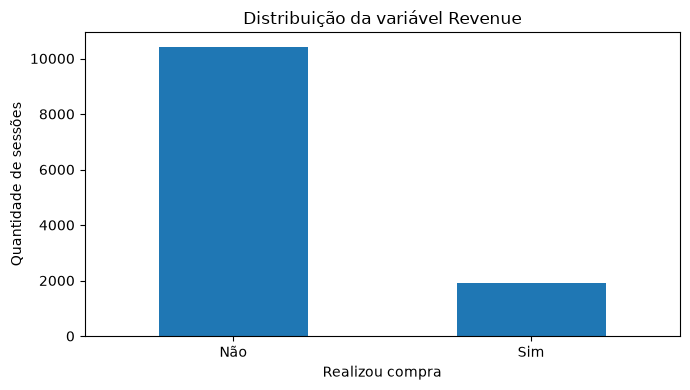

In [3]:
# Visualizar a distribuição da variável Revenue.

contagem = df["Revenue"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))

contagem.plot(kind="bar", ax=ax)

ax.set_title("Distribuição da variável Revenue")
ax.set_xlabel("Realizou compra")
ax.set_ylabel("Quantidade de sessões")
ax.set_xticklabels(["Não", "Sim"], rotation=0)

plt.tight_layout()
plt.savefig(saida / "distribuicao_revenue.png", dpi=300)
plt.show()

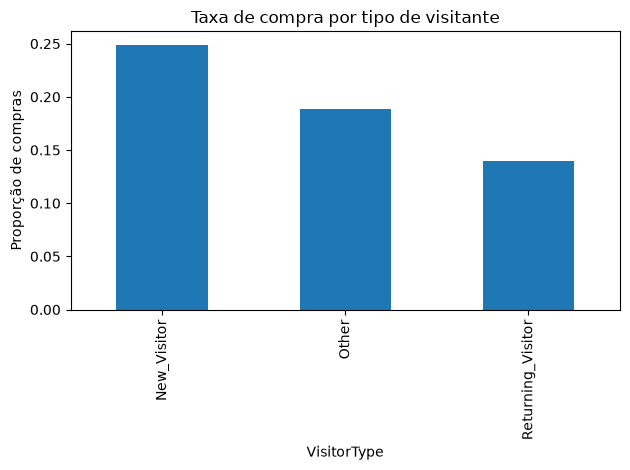

In [4]:
# Visualizar a taxa de compra por tipo de visitante.

taxa = df.groupby("VisitorType")["Revenue"].mean()

taxa.plot(kind="bar")
plt.title("Taxa de compra por tipo de visitante")
plt.ylabel("Proporção de compras")
plt.tight_layout()
plt.savefig(saida / "taxa_visitante.png", dpi=300)
plt.show()

Pré-Processamento

In [5]:
# Não foram encontrados valores ausentes ou inconsistentes.

# Ainda há atributos do tipo texto que precisam ser convertidos para o tipo categórico: month, VisitorType, Revenue e Weekend.

# O mês será convertido para o seu próprio numero. Por exemplo, Janeiro será 1, Fevereiro será 2 e assim por diante. O mês de Dezembro será 12.

# O atributo Weekend será convertido para 0 e 1, onde 0 significa que o usuário não visitou o site no final de semana e 1 significa que o usuário visitou o site no final de semana.

# O atributo Revenue será convertido para 0 e 1, onde 0 significa que o usuário não realizou uma compra e 1 significa que o usuário realizou uma compra.

# O atributo VisitorType será convertido para 0, 1 e 2, onde 0 significa que o usuário é um visitante novo, 1 significa que o usuário é um visitante recorrente e 2 significa que o usuário é um visitante de retorno.

# Cria uma nova tabela sem modificar a original
df_convertido = df.copy()

# Converte os nomes dos meses para números
meses = {
    "Jan": 1,
    "Feb": 2,
    "Mar": 3,
    "Apr": 4,
    "May": 5,
    "June": 6,
    "Jul": 7,
    "Aug": 8,
    "Sep": 9,
    "Oct": 10,
    "Nov": 11,
    "Dec": 12,
}

# Categorias existentes na base
tipos_visitante = {
    "New_Visitor": 0,
    "Returning_Visitor": 1,
    "Other": 2,
}

booleanos = {
    "true": 1,
    "false": 0,
}

df_convertido["Month"] = df_convertido["Month"].map(meses)

df_convertido["VisitorType"] = df_convertido["VisitorType"].map(tipos_visitante)

# Funciona tanto para valores booleanos quanto para textos TRUE/FALSE
for coluna in ["Weekend", "Revenue"]:
    df_convertido[coluna] = (
        df_convertido[coluna].astype("string").str.strip().str.lower().map(booleanos)
    )

# Exibe as primeiras linhas da nova tabela
display(df_convertido.head())

# Confira os tipos e possíveis valores não reconhecidos
display(df_convertido[["Month", "VisitorType", "Weekend", "Revenue"]].info())
display(df_convertido[["Month", "VisitorType", "Weekend", "Revenue"]].isna().sum())

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,2,1,1,1,1,1,0,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,2,2,2,1,2,1,0,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,2,4,1,9,3,1,0,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,2,3,2,2,4,1,0,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,2,3,3,1,4,1,1,0


<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Month        12330 non-null  int64
 1   VisitorType  12330 non-null  int64
 2   Weekend      12330 non-null  int64
 3   Revenue      12330 non-null  int64
dtypes: int64(4)
memory usage: 385.4 KB


None

Month          0
VisitorType    0
Weekend        0
Revenue        0
dtype: int64

In [ ]:
# Salva a nova tabela em um arquivo CSV

df_convertido.to_csv(
    raiz / "dados" / "online_shoppers_convertido.csv", index=False, encoding="utf-8"
)